# Lecture 9: Production trees and utility functions

The ninth model gives firms a richer technology and households a richer demand system. Value added now combines four factors in a two-level CES tree, and households buy subsistence quantities of each good before spending the rest of their budget, a linear expenditure system. The assignment raises the value added tax in industry and services.

:::{admonition} Watch the lectures
:class: tip

- 📺 Lecture: [CGE models: new production trees and new utility functions](https://www.youtube.com/watch?v=H8LPC8_djSg)
- ✅ Correction: [Production trees and utility functions, correction](https://www.youtube.com/watch?v=KKPTw71pZko)
- 🎓 Full course playlist: [Antoine Bouet's CGE lectures](https://www.youtube.com/playlist?list=PLfV47vAW_jrc57x1O36Pz9vol86f0YUXW)
:::

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import cge_modeling as cm

## The economy

The model extends the eighth notebook in two places, production and household demand. Trade, the government and the transfers are unchanged.

The two factors become four: land, unskilled labor, skilled labor and capital. Each sector produces along a production tree.

- Output $Y_i$ is a Leontief combination of value added $VA_i$ and the intermediate bundle $IC_i$, as before.
- Value added is a CES aggregate of land $LAND_i$, unskilled labor $LD_i$ and a composite factor $Q_i$, with elasticity of substitution $\sigma^{va} = 1.1$.
- The composite factor is a CES aggregate of skilled labor $SKLD_i$ and capital $KD_i$, with elasticity $\sigma^{cap} = 0.6$.

The low elasticity in the bottom nest makes skilled labor and capital complements, and their composite substitutes for unskilled labor. Only agriculture uses land.

Households switch from Cobb-Douglas demand to a linear expenditure system (LES). They first buy a subsistence quantity $C^{min}_i$ of each good, then split the rest of their consumption budget with fixed marginal shares $\gamma_i$:

$$P_i \cdot (C_i - C^{min}_i) = \gamma_i \cdot \left((1 - mps) \cdot DISP\_INC - \sum_j P_j \cdot C^{min}_j\right).$$

With Cobb-Douglas demand every good has an income elasticity of 1. With LES, a change in income moves only the spending above subsistence, so a good with a large subsistence quantity has an income elasticity below 1. Investment and government demand stay Cobb-Douglas.

### Variables

Six variables are new: land demand, skilled labor demand, the composite factor and its price, the wage of skilled labor and the return to land. $W$ is now the wage of unskilled labor.

In [2]:
sectors = ["Agr", "Ind", "Serv"]
mod = cm.CGEModel(coords={"i": sectors, "j": sectors})

with mod:
    Y = cm.Variable("Y", dims="i", description="Output of sector <dim:i>")
    VA = cm.Variable("VA", dims="i", description="Value added in sector <dim:i>")
    IC = cm.Variable("IC", dims="i", description="Intermediate bundle used by sector <dim:i>")
    CIJ = cm.Variable("CIJ", dims=("i", "j"), description="Good <dim:i> used by sector <dim:j>")
    LAND = cm.Variable("LAND", dims="i", description="Land demand of sector <dim:i>")
    LD = cm.Variable("LD", dims="i", description="Unskilled labor demand of sector <dim:i>")
    Q = cm.Variable("Q", dims="i", description="Composite of skilled labor and capital in sector <dim:i>")
    SKLD = cm.Variable("SKLD", dims="i", description="Skilled labor demand of sector <dim:i>")
    KD = cm.Variable("KD", dims="i", description="Capital demand of sector <dim:i>")
    P = cm.Variable("P", dims="i", description="Consumer price of good <dim:i>")
    PY = cm.Variable("PY", dims="i", description="Producer price of the output of sector <dim:i>")
    PVA = cm.Variable("PVA", dims="i", description="Price of value added in sector <dim:i>")
    PQ = cm.Variable("PQ", dims="i", description="Price of the composite factor in sector <dim:i>")
    PIC = cm.Variable("PIC", dims="i", description="Price of the intermediate bundle in sector <dim:i>")
    DEMTOT = cm.Variable("DEMTOT", dims="i", description="Absorption of good <dim:i>")
    PDEMTOT = cm.Variable("PDEMTOT", dims="i", description="Price of absorption of good <dim:i> before tax")
    D = cm.Variable("D", dims="i", description="Domestic variety of good <dim:i> bought at home")
    PD = cm.Variable("PD", dims="i", description="Domestic price of good <dim:i>")
    XD = cm.Variable("XD", dims="i", description="Domestic sales of sector <dim:i>")
    M = cm.Variable("M", dims="i", description="Imports of good <dim:i>")
    PM = cm.Variable("PM", dims="i", description="Domestic price of imports of good <dim:i>")
    X = cm.Variable("X", dims="i", description="Exports of good <dim:i>")
    PX = cm.Variable("PX", dims="i", description="Domestic price of exports of good <dim:i>")
    PWM = cm.Variable("PWM", dims="i", description="World price of imports of good <dim:i>")
    PWX = cm.Variable("PWX", dims="i", description="World price of exports of good <dim:i>")
    W = cm.Variable("W", description="Wage of unskilled labor")
    WS = cm.Variable("WS", description="Wage of skilled labor")
    R = cm.Variable("R", description="Return to capital")
    RLAND = cm.Variable("RLAND", description="Return to land")
    INC = cm.Variable("INC", description="Gross income of households")
    DISP_INC = cm.Variable("DISP_INC",
                           latex_name=r"\mathrm{DISP\_INC}",
                           description="Disposable income of households")
    savings = cm.Variable("savings", description="Household saving")
    C = cm.Variable("C", dims="i", description="Household consumption of good <dim:i>")
    U = cm.Variable("U", description="Utility of households")
    BUDG_EXP = cm.Variable("BUDG_EXP",
                           latex_name=r"\mathrm{BUDG\_EXP}",
                           description="Government spending")
    CG = cm.Variable("CG", dims="i", description="Government purchases of good <dim:i>")
    INV = cm.Variable("INV", description="Total investment")
    CK = cm.Variable("CK", dims="i", description="Investment demand for good <dim:i>")
    tradesold = cm.Variable("tradesold", description="Trade balance, exports minus imports")
    curr_acc = cm.Variable("curr_acc",
                           latex_name=r"\mathrm{curr\_acc}",
                           description="Current account, the trade balance plus transfers from abroad")
    Leon = cm.Variable("Leon", description="Walras check variable")

mod.summary("variables")

\(\textbf{Symbol}\),\(\textbf{Description}\)
\(Y_{i}\),\(\text{Output}\) \(\text{of}\) \(\text{sector}\) \(\text{i}\)
\(\mathrm{VA}_{i}\),\(\text{Value}\) \(\text{added}\) \(\text{in}\) \(\text{sector}\) \(\text{i}\)
\(\mathrm{IC}_{i}\),\(\text{Intermediate}\) \(\text{bundle}\) \(\text{used}\) \(\text{by}\) \(\text{sector}\) \(\text{i}\)
"\(\mathrm{CIJ}_{i, j}\)",\(\text{Good}\) \(\text{i}\) \(\text{used}\) \(\text{by}\) \(\text{sector}\) \(\text{j}\)
\(\mathrm{LAND}_{i}\),\(\text{Land}\) \(\text{demand}\) \(\text{of}\) \(\text{sector}\) \(\text{i}\)
\(\mathrm{LD}_{i}\),\(\text{Unskilled}\) \(\text{labor}\) \(\text{demand}\) \(\text{of}\) \(\text{sector}\) \(\text{i}\)
\(Q_{i}\),\(\text{Composite}\) \(\text{of}\) \(\text{skilled}\) \(\text{labor}\) \(\text{and}\) \(\text{capital}\) \(\text{in}\) \(\text{sector}\) \(\text{i}\)
\(\mathrm{SKLD}_{i}\),\(\text{Skilled}\) \(\text{labor}\) \(\text{demand}\) \(\text{of}\) \(\text{sector}\) \(\text{i}\)
\(\mathrm{KD}_{i}\),\(\text{Capital}\) \(\text{demand}\) \(\text{of}\) \(\text{sector}\) \(\text{i}\)
\(P_{i}\),\(\text{Consumer}\) \(\text{price}\) \(\text{of}\) \(\text{good}\) \(\text{i}\)


### Parameters

The new parameters are the share parameters of the two value added nests, the two nest elasticities, the subsistence quantities $C^{min}_i$, and the supplies of skilled labor and land.

In [3]:
with mod:
    psi_VA = cm.Parameter("psi_VA", dims="i", description="Value added per unit of output in sector <dim:i>")
    psi_IC = cm.Parameter("psi_IC", dims="i", description="Intermediate bundle per unit of output in sector <dim:i>")
    psi_IJC = cm.Parameter("psi_IJC",
                           dims=("i", "j"),
                           description="Good <dim:i> per unit of the intermediate bundle of sector <dim:j>")
    a_land = cm.Parameter("a_land",
                          dims="i",
                          latex_name="a^{Land}",
                          description="Share parameter of land in value added of sector <dim:i>")
    a_l = cm.Parameter("a_l",
                       dims="i",
                       latex_name="a^L",
                       description="Share parameter of unskilled labor in value added of sector <dim:i>")
    a_q = cm.Parameter("a_q",
                       dims="i",
                       latex_name="a^Q",
                       description="Share parameter of the composite factor in value added of sector <dim:i>")
    a_skld = cm.Parameter("a_skld",
                          dims="i",
                          latex_name="a^{SKLD}",
                          description="Share parameter of skilled labor in the composite factor of sector <dim:i>")
    a_kd = cm.Parameter("a_kd",
                        dims="i",
                        latex_name="a^{KD}",
                        description="Share parameter of capital in the composite factor of sector <dim:i>")
    sigma_va = cm.Parameter("sigma_va",
                            dims="i",
                            latex_name=r"\sigma^{va}",
                            description="Elasticity of substitution in value added of sector <dim:i>")
    sigma_cap = cm.Parameter("sigma_cap",
                             dims="i",
                             latex_name=r"\sigma^{cap}",
                             description="Elasticity of substitution between skilled labor and capital in sector <dim:i>")
    gamma = cm.Parameter("gamma", dims="i", description="Marginal budget share of good <dim:i>")
    cmin = cm.Parameter("cmin",
                        dims="i",
                        latex_name="C^{min}",
                        description="Subsistence consumption of good <dim:i>")
    alpha_g = cm.Parameter("alpha_g",
                           dims="i",
                           latex_name=r"\alpha^G",
                           description="Government budget share of good <dim:i>")
    alpha_k = cm.Parameter("alpha_k",
                           dims="i",
                           latex_name=r"\alpha^K",
                           description="Investment budget share of good <dim:i>")
    mps = cm.Parameter("mps", description="Marginal propensity to save")
    itr = cm.Parameter("itr", description="Income tax rate")
    tau = cm.Parameter("tau", dims="i", description="Indirect tax rate on absorption of good <dim:i>")
    tm = cm.Parameter("tm", dims="i", description="Import duty rate on good <dim:i>")
    te = cm.Parameter("te", dims="i", description="Export tax rate on good <dim:i>")
    tva = cm.Parameter("tva", dims="i", description="Value added tax rate in sector <dim:i>")
    a_d = cm.Parameter("a_d",
                       dims="i",
                       latex_name="a^D",
                       description="Share parameter of the domestic variety of good <dim:i>")
    a_m = cm.Parameter("a_m",
                       dims="i",
                       latex_name="a^M",
                       description="Share parameter of imports of good <dim:i>")
    a_xd = cm.Parameter("a_xd",
                        dims="i",
                        latex_name="a^{XD}",
                        description="Share parameter of domestic sales of sector <dim:i>")
    a_x = cm.Parameter("a_x",
                       dims="i",
                       latex_name="a^X",
                       description="Share parameter of exports of sector <dim:i>")
    sigma_arm = cm.Parameter("sigma_arm",
                             dims="i",
                             latex_name=r"\sigma^{arm}",
                             description="Elasticity of substitution between domestic and imported good <dim:i>")
    sigma_cet = cm.Parameter("sigma_cet",
                             dims="i",
                             latex_name=r"\sigma^{cet}",
                             description="Elasticity of transformation between domestic sales and exports of sector <dim:i>")
    f_m = cm.Parameter("f_m",
                       dims="i",
                       latex_name="f^M",
                       description="Scale of the rest of the world's supply of good <dim:i>")
    f_x = cm.Parameter("f_x",
                       dims="i",
                       latex_name="f^X",
                       description="Scale of the rest of the world's demand for good <dim:i>")
    sigma_m = cm.Parameter("sigma_m",
                           dims="i",
                           latex_name=r"\sigma^M",
                           description="Price elasticity of the rest of the world's supply of good <dim:i>")
    sigma_x = cm.Parameter("sigma_x",
                           dims="i",
                           latex_name=r"\sigma^X",
                           description="Price elasticity of the rest of the world's demand for good <dim:i>")
    remittances = cm.Parameter("remittances", description="Remittances to households, in foreign currency")
    transf_G_hh = cm.Parameter("transf_G_hh",
                               latex_name=r"transf_{G,hh}",
                               description="Transfer from the government to households")
    transf_RoW_G = cm.Parameter("transf_RoW_G",
                                latex_name=r"transf_{RoW,G}",
                                description="Transfer from the rest of the world to the government, in foreign currency")
    e = cm.Parameter("e", description="Exchange rate")
    pubsold = cm.Parameter("pubsold", description="Public balance, revenue minus spending")
    LS = cm.Parameter("LS", description="Supply of unskilled labor")
    SKS = cm.Parameter("SKS", description="Supply of skilled labor")
    KS = cm.Parameter("KS", description="Supply of capital")
    LANDS = cm.Parameter("LANDS", description="Supply of land")
    PD_Agr = cm.Parameter("PD_Agr",
                          latex_name=r"\bar{PD}_{Agr}",
                          description="Domestic price of agriculture, the numeraire")

mod.summary("parameters")

\(\textbf{Symbol}\),\(\textbf{Description}\)
"\(\psi_{\mathrm{VA}, i}\)",\(\text{Value}\) \(\text{added}\) \(\text{per}\) \(\text{unit}\) \(\text{of}\) \(\text{output}\) \(\text{in}\) \(\text{sector}\) \(\text{i}\)
"\(\psi_{\mathrm{IC}, i}\)",\(\text{Intermediate}\) \(\text{bundle}\) \(\text{per}\) \(\text{unit}\) \(\text{of}\) \(\text{output}\) \(\text{in}\) \(\text{sector}\) \(\text{i}\)
"\(\psi_{\mathrm{IJC}, i, j}\)",\(\text{Good}\) \(\text{i}\) \(\text{per}\) \(\text{unit}\) \(\text{of}\) \(\text{the}\) \(\text{intermediate}\) \(\text{bundle}\) \(\text{of}\) \(\text{sector}\) \(\text{j}\)
\(a^{Land}_{i}\),\(\text{Share}\) \(\text{parameter}\) \(\text{of}\) \(\text{land}\) \(\text{in}\) \(\text{value}\) \(\text{added}\) \(\text{of}\) \(\text{sector}\) \(\text{i}\)
\(a^L_{i}\),\(\text{Share}\) \(\text{parameter}\) \(\text{of}\) \(\text{unskilled}\) \(\text{labor}\) \(\text{in}\) \(\text{value}\) \(\text{added}\) \(\text{of}\) \(\text{sector}\) \(\text{i}\)
\(a^Q_{i}\),\(\text{Share}\) \(\text{parameter}\) \(\text{of}\) \(\text{the}\) \(\text{composite}\) \(\text{factor}\) \(\text{in}\) \(\text{value}\) \(\text{added}\) \(\text{of}\) \(\text{sector}\) \(\text{i}\)
\(a^{SKLD}_{i}\),\(\text{Share}\) \(\text{parameter}\) \(\text{of}\) \(\text{skilled}\) \(\text{labor}\) \(\text{in}\) \(\text{the}\) \(\text{composite}\) \(\text{factor}\) \(\text{of}\) \(\text{sector}\) \(\text{i}\)
\(a^{KD}_{i}\),\(\text{Share}\) \(\text{parameter}\) \(\text{of}\) \(\text{capital}\) \(\text{in}\) \(\text{the}\) \(\text{composite}\) \(\text{factor}\) \(\text{of}\) \(\text{sector}\) \(\text{i}\)
\(\sigma^{va}_{i}\),\(\text{Elasticity}\) \(\text{of}\) \(\text{substitution}\) \(\text{in}\) \(\text{value}\) \(\text{added}\) \(\text{of}\) \(\text{sector}\) \(\text{i}\)
\(\sigma^{cap}_{i}\),\(\text{Elasticity}\) \(\text{of}\) \(\text{substitution}\) \(\text{between}\) \(\text{skilled}\) \(\text{labor}\) \(\text{and}\) \(\text{capital}\) \(\text{in}\) \(\text{sector}\) \(\text{i}\)


### Equations

Each CES nest in the value added block has a value identity and one demand per input, in the form of the seventh notebook's Armington block. VAT applies to every factor payment. For value added and the composite factor,

$$\begin{aligned}
PVA_i \cdot VA_i &= W \cdot (1 + tva_i) \cdot LD_i + PQ_i \cdot Q_i + RLAND \cdot (1 + tva_i) \cdot LAND_i \\
LD_i &= a^L_i \cdot VA_i \cdot \left(\frac{PVA_i}{W \cdot (1 + tva_i)}\right)^{\sigma^{va}_i} \\
PQ_i \cdot Q_i &= R \cdot (1 + tva_i) \cdot KD_i + WS \cdot (1 + tva_i) \cdot SKLD_i \\
KD_i &= a^{KD}_i \cdot Q_i \cdot \left(\frac{PQ_i}{R \cdot (1 + tva_i)}\right)^{\sigma^{cap}_i}
\end{aligned}$$

and the demands for $Q_i$, $LAND_i$ and $SKLD_i$ take the same form. The course program writes the land demand only for sectors that use land. Here every sector has one, and the share parameter $a^{Land}_i$ is zero in industry and services, so their land demand is zero.

Income adds the payments to all four factors, the government collects VAT on all of them, and each factor has its own market. The consumption equation takes the LES form above, and utility becomes $U = \prod_i (C_i - C^{min}_i)^{\gamma_i}$.

In [4]:
with mod:
    cm.Equation("Value added demand", VA, psi_VA * Y)
    cm.Equation("Intermediate bundle demand", IC, psi_IC * Y)
    cm.Equation("Zero profit", PY * Y, PVA * VA + PIC * IC)

    cm.Equation("Value added cost", PVA * VA, W * (1 + tva) * LD + PQ * Q + RLAND * (1 + tva) * LAND)
    cm.Equation("Unskilled labor demand",
                W * (1 + tva) * LD,
                W * (1 + tva) * a_l * VA * (PVA / (W * (1 + tva))) ** sigma_va)
    cm.Equation("Composite factor demand", PQ * Q, PQ * a_q * VA * (PVA / PQ) ** sigma_va)
    cm.Equation("Land demand",
                RLAND * (1 + tva) * LAND,
                RLAND * (1 + tva) * a_land * VA * (PVA / (RLAND * (1 + tva))) ** sigma_va)

    cm.Equation("Composite factor cost", PQ * Q, R * (1 + tva) * KD + WS * (1 + tva) * SKLD)
    cm.Equation("Skilled labor demand",
                WS * (1 + tva) * SKLD,
                WS * (1 + tva) * a_skld * Q * (PQ / (WS * (1 + tva))) ** sigma_cap)
    cm.Equation("Capital demand",
                R * (1 + tva) * KD,
                R * (1 + tva) * a_kd * Q * (PQ / (R * (1 + tva))) ** sigma_cap)

    cm.Equation("Intermediate bundle price", (PIC * IC).rename(i="j"), (P * CIJ).sum("i"))
    cm.Equation("Intermediate input demand", CIJ, psi_IJC * IC.rename(i="j"))

    cm.Equation("Output value", PY * Y, PD * XD + PX * X)
    cm.Equation("Domestic supply", PD * XD, PD * a_xd * Y * (PD / PY) ** sigma_cet)
    cm.Equation("Export supply", PX * X, PX * a_x * Y * (PX / PY) ** sigma_cet)

    cm.Equation("Absorption", DEMTOT, C + CG + CK + CIJ.sum("j"))
    cm.Equation("Absorption value", PDEMTOT * DEMTOT, PD * D + PM * M)
    cm.Equation("Domestic demand", PD * D, PD * a_d * DEMTOT * (PDEMTOT / PD) ** sigma_arm)
    cm.Equation("Import demand", PM * M, PM * a_m * DEMTOT * (PDEMTOT / PM) ** sigma_arm)
    cm.Equation("Domestic market clearing", XD, D)

    cm.Equation("Tax wedge", PDEMTOT * (1 + tau), P)
    cm.Equation("Import price", PM, e * PWM * (1 + tm))
    cm.Equation("Export price", PX * (1 + te), e * PWX)
    cm.Equation("Import supply", M, f_m * PWM**sigma_m)
    cm.Equation("Export demand", X, f_x * PWX ** (-sigma_x))

    cm.Equation("Income", INC, W * LS + WS * SKS + R * KS + RLAND * LANDS + e * remittances)
    cm.Equation("Disposable income", DISP_INC, (1 - itr) * INC + transf_G_hh)
    cm.Equation("Saving", savings, mps * DISP_INC)
    cm.Equation("Consumption", P * (C - cmin), gamma * ((1 - mps) * DISP_INC - (P * cmin).sum()))
    cm.Equation("Utility", U, ((C - cmin) ** gamma).prod())
    cm.Equation("Investment demand", P * CK, alpha_k * INV)
    cm.Equation("Public balance",
                pubsold,
                e * transf_RoW_G
                + itr * INC
                + (tau * PDEMTOT * DEMTOT).sum()
                + (tm * e * PWM * M).sum()
                + (te * PX * X).sum()
                + (tva * (W * LD + WS * SKLD + R * KD + RLAND * LAND)).sum()
                - BUDG_EXP
                - transf_G_hh)
    cm.Equation("Government demand", P * CG, alpha_g * BUDG_EXP)
    cm.Equation("Trade balance", tradesold, e * (PWX * X - PWM * M).sum())
    cm.Equation("Current account", curr_acc, tradesold + e * remittances + e * transf_RoW_G)

    cm.Equation("Unskilled labor market clearing", LS, LD.sum() + Leon)
    cm.Equation("Skilled labor market clearing", SKS, SKLD.sum())
    cm.Equation("Capital market clearing", KS, KD.sum())
    cm.Equation("Land market clearing", LANDS, LAND.sum())
    cm.Equation("Macroeconomic balance", savings - INV + pubsold, curr_acc)
    cm.Equation("Numeraire", PD.sel(i="Agr"), PD_Agr)

mod.equation_table()

,\(\textbf{Name}\),\(\textbf{Equation}\)
\(1\),\(\text{Value}\) \(\text{added}\) \(\text{demand}\),"\(\mathrm{VA}_{i} = \psi_{\mathrm{VA}, i} \cdot Y_{i}\)"
\(2\),\(\text{Intermediate}\) \(\text{bundle}\) \(\text{demand}\),"\(\mathrm{IC}_{i} = \psi_{\mathrm{IC}, i} \cdot Y_{i}\)"
\(3\),\(\text{Zero}\) \(\text{profit}\),\(\mathrm{PY}_{i} \cdot Y_{i} = \mathrm{PVA}_{i} \cdot \mathrm{VA}_{i} + \mathrm{PIC}_{i} \cdot \mathrm{IC}_{i}\)
\(4\),\(\text{Value}\) \(\text{added}\) \(\text{cost}\),\(\mathrm{PVA}_{i} \cdot \mathrm{VA}_{i} = W \left(1 + \mathrm{tva}_{i}\right) \mathrm{LD}_{i} + \mathrm{PQ}_{i} \cdot Q_{i} + \mathrm{RLAND} \left(1 + \mathrm{tva}_{i}\right) \mathrm{LAND}_{i}\)
\(5\),\(\text{Unskilled}\) \(\text{labor}\) \(\text{demand}\),\(W \left(1 + \mathrm{tva}_{i}\right) \mathrm{LD}_{i} = W \left(1 + \mathrm{tva}_{i}\right) a^L_{i} \cdot \mathrm{VA}_{i} \left(\frac{\mathrm{PVA}_{i}}{W \left(1 + \mathrm{tva}_{i}\right)}\right)^{\sigma^{va}_{i}}\)
\(6\),\(\text{Composite}\) \(\text{factor}\) \(\text{demand}\),\(\mathrm{PQ}_{i} \cdot Q_{i} = \mathrm{PQ}_{i} \cdot a^Q_{i} \cdot \mathrm{VA}_{i} \left(\frac{\mathrm{PVA}_{i}}{\mathrm{PQ}_{i}}\right)^{\sigma^{va}_{i}}\)
\(7\),\(\text{Land}\) \(\text{demand}\),\(\mathrm{RLAND} \left(1 + \mathrm{tva}_{i}\right) \mathrm{LAND}_{i} = \mathrm{RLAND} \left(1 + \mathrm{tva}_{i}\right) a^{Land}_{i} \cdot \mathrm{VA}_{i} \left(\frac{\mathrm{PVA}_{i}}{\mathrm{RLAND} \left(1 + \mathrm{tva}_{i}\right)}\right)^{\sigma^{va}_{i}}\)
\(8\),\(\text{Composite}\) \(\text{factor}\) \(\text{cost}\),\(\mathrm{PQ}_{i} \cdot Q_{i} = R \left(1 + \mathrm{tva}_{i}\right) \mathrm{KD}_{i} + \mathrm{WS} \left(1 + \mathrm{tva}_{i}\right) \mathrm{SKLD}_{i}\)
\(9\),\(\text{Skilled}\) \(\text{labor}\) \(\text{demand}\),\(\mathrm{WS} \left(1 + \mathrm{tva}_{i}\right) \mathrm{SKLD}_{i} = \mathrm{WS} \left(1 + \mathrm{tva}_{i}\right) a^{SKLD}_{i} \cdot Q_{i} \left(\frac{\mathrm{PQ}_{i}}{\mathrm{WS} \left(1 + \mathrm{tva}_{i}\right)}\right)^{\sigma^{cap}_{i}}\)
\(10\),\(\text{Capital}\) \(\text{demand}\),\(R \left(1 + \mathrm{tva}_{i}\right) \mathrm{KD}_{i} = R \left(1 + \mathrm{tva}_{i}\right) a^{KD}_{i} \cdot Q_{i} \left(\frac{\mathrm{PQ}_{i}}{R \left(1 + \mathrm{tva}_{i}\right)}\right)^{\sigma^{cap}_{i}}\)


In [5]:
mod.compile();

Compiling a model with 103 equations, 103 variables, 102 parameters


## Data

The lecture's SAM is the eighth notebook's with the two factors split into four. Land earns 600, all in agriculture, and unskilled labor, skilled labor and capital earn 6070, 1400 and 1200. Every other entry is unchanged, and so are the tax collections and the trade elasticities. The two nest elasticities come from the lecture's production tree.

The slides do not give the subsistence quantities. Subsistence shares of benchmark consumption of 0.8 for agriculture, 0.6 for industry and 0.2 for services reproduce the correction's results, and this notebook uses them. Nearby shares fit almost as well, so these are an inference, not the course's values.

In [6]:
factors = ["Land", "LD", "SKLD", "KD"]
accounts = [*factors, "Hld", "Gvt", *sectors, "Inv", "RoW"]
sam = pd.DataFrame(0.0, index=accounts, columns=accounts)
sam.loc["Land", sectors] = [600.0, 0.0, 0.0]
sam.loc["LD", sectors] = [450.0, 1560.0, 4060.0]
sam.loc["SKLD", sectors] = [200.0, 900.0, 300.0]
sam.loc["KD", sectors] = [50.0, 900.0, 250.0]
sam.loc["Hld", [*factors, "Gvt", "RoW"]] = [600.0, 6070.0, 1400.0, 1200.0, 100.0, 500.0]
sam.loc["Gvt", ["Hld", *sectors, "RoW"]] = [1400.0, 215.0, 1505.0, 370.0, 50.0]
sam.loc[sectors, "Hld"] = [1700.0, 1200.0, 3400.0]
sam.loc[sectors, "Gvt"] = [450.0, 1000.0, 2790.0]
sam.loc[sectors, "Inv"] = [200.0, 745.0, 100.0]
sam.loc[sectors, "RoW"] = [315.0, 30.0, 100.0]
sam.loc[sectors, sectors] = [[1120.0, 930.0, 1100.0],
                             [2200.0, 3120.0, 3300.0],
                             [830.0, 2250.0, 1100.0]]
sam.loc["Inv", ["Hld", "Gvt", "RoW"]] = [2170.0, -800.0, -325.0]
sam.loc["RoW", sectors] = [150.0, 430.0, 90.0]

tax_collections = pd.DataFrame({"import_duty": [0.0, 300.0, 0.0],
                                "export_tax": [15.0, 45.0, 0.0],
                                "vat": [50.0, 140.0, 90.0]},
                               index=sectors)
elasticities = pd.DataFrame({"sigma_arm": 3.0,
                             "sigma_cet": 3.0,
                             "sigma_m": 3.0,
                             "sigma_x": 3.0,
                             "sigma_va": 1.1,
                             "sigma_cap": 0.6},
                            index=sectors)
subsistence_shares = pd.Series([0.8, 0.6, 0.2], index=sectors)

assert np.allclose(sam.sum(axis=0), sam.sum(axis=1))
sam

,Land,LD,SKLD,KD,Hld,Gvt,Agr,Ind,Serv,Inv,RoW
Land,0.0,0.0,0.0,0.0,0.0,0.0,600.0,0.0,0.0,0.0,0.0
LD,0.0,0.0,0.0,0.0,0.0,0.0,450.0,1560.0,4060.0,0.0,0.0
SKLD,0.0,0.0,0.0,0.0,0.0,0.0,200.0,900.0,300.0,0.0,0.0
KD,0.0,0.0,0.0,0.0,0.0,0.0,50.0,900.0,250.0,0.0,0.0
Hld,600.0,6070.0,1400.0,1200.0,0.0,100.0,0.0,0.0,0.0,0.0,500.0
Gvt,0.0,0.0,0.0,0.0,1400.0,0.0,215.0,1505.0,370.0,0.0,50.0
Agr,0.0,0.0,0.0,0.0,1700.0,450.0,1120.0,930.0,1100.0,200.0,315.0
Ind,0.0,0.0,0.0,0.0,1200.0,1000.0,2200.0,3120.0,3300.0,745.0,30.0
Serv,0.0,0.0,0.0,0.0,3400.0,2790.0,830.0,2250.0,1100.0,100.0,100.0
Inv,0.0,0.0,0.0,0.0,2170.0,-800.0,0.0,0.0,0.0,0.0,-325.0


## Calibration

The calibration follows the eighth notebook. The four factor prices start at 1, and so do the prices of value added and of the composite factor, so benchmark value added and the composite include the VAT on the factors they use. Each CES share parameter is a benchmark quantity ratio times a relative price raised to minus the nest elasticity, for example

$$a^{KD}_i = \frac{KD_{0,i}}{Q_{0,i}} \cdot \left(\frac{PQ_{0,i}}{R_0 \cdot (1 + tva_i)}\right)^{-\sigma^{cap}_i}.$$

Land's share parameter is zero wherever the SAM records no land. The subsistence quantities are the shares above times benchmark consumption, and the marginal budget shares follow from benchmark spending above subsistence:

$$\gamma_i = \frac{P_{0,i} \cdot (C_{0,i} - C^{min}_i)}{(1 - mps) \cdot DISP\_INC_0 - \sum_j P_{0,j} \cdot C^{min}_j}.$$

In [7]:
def calibrate_model(mod, sam, tax_collections, elasticities, subsistence_shares):
    LAND = sam.loc["Land", sectors].values
    LD = sam.loc["LD", sectors].values
    SKLD = sam.loc["SKLD", sectors].values
    KD = sam.loc["KD", sectors].values
    CIJ = sam.loc[sectors, sectors].values
    C = sam.loc[sectors, "Hld"].values
    CG = sam.loc[sectors, "Gvt"].values
    CK = sam.loc[sectors, "Inv"].values
    IMPDUTY = tax_collections["import_duty"].values
    EXPTAX = tax_collections["export_tax"].values
    VATCOLL = tax_collections["vat"].values
    INDTAX = sam.loc["Gvt", sectors].values - IMPDUTY - EXPTAX - VATCOLL
    DIRTAX = sam.loc["Gvt", "Hld"]
    savings = sam.loc["Inv", "Hld"]
    remittances = sam.loc["Hld", "RoW"]
    transf_G_hh = sam.loc["Hld", "Gvt"]
    transf_RoW_G = sam.loc["Gvt", "RoW"]
    M = sam.loc["RoW", sectors].values + IMPDUTY
    X = sam.loc[sectors, "RoW"].values
    Y = sam[sectors].sum(axis=0).values - sam.loc["RoW", sectors].values - IMPDUTY

    sigma_arm = elasticities["sigma_arm"].values
    sigma_cet = elasticities["sigma_cet"].values
    sigma_m = elasticities["sigma_m"].values
    sigma_x = elasticities["sigma_x"].values
    sigma_va = elasticities["sigma_va"].values
    sigma_cap = elasticities["sigma_cap"].values

    P = np.ones(len(sectors))
    PD = np.ones(len(sectors))
    PX = np.ones(len(sectors))
    PVA = np.ones(len(sectors))
    PQ = np.ones(len(sectors))
    PIC = np.ones(len(sectors))
    W = 1.0
    WS = 1.0
    R = 1.0
    RLAND = 1.0
    e = 1.0

    LS = LD.sum()
    SKS = SKLD.sum()
    KS = KD.sum()
    LANDS = LAND.sum()
    factor_cost = W * LD + WS * SKLD + R * KD + RLAND * LAND
    tva = VATCOLL / factor_cost
    tau = INDTAX / (P * Y - INDTAX)

    Q = (1 + tva) * (R * KD + WS * SKLD) / PQ
    VA = (1 + tva) * factor_cost / PVA
    a_land = LAND / VA * (PVA / (RLAND * (1 + tva))) ** (-sigma_va)
    a_l = LD / VA * (PVA / (W * (1 + tva))) ** (-sigma_va)
    a_q = Q / VA * (PVA / PQ) ** (-sigma_va)
    a_skld = SKLD / Q * (PQ / (WS * (1 + tva))) ** (-sigma_cap)
    a_kd = KD / Q * (PQ / (R * (1 + tva))) ** (-sigma_cap)

    IC = (P[:, None] * CIJ).sum(axis=0) / PIC
    PY = (PVA * VA + PIC * IC) / Y
    psi_VA = VA / Y
    psi_IC = IC / Y
    psi_IJC = CIJ / IC[None, :]

    te = EXPTAX / (PX * X)
    XD = (PY * Y - PX * X) / PD
    D = XD
    PDEMTOT = P / (1 + tau)
    DEMTOT = C + CG + CK + CIJ.sum(axis=1)
    PM = (PDEMTOT * DEMTOT - PD * D) / M

    a_x = X / Y * (PX / PY) ** (-sigma_cet)
    a_xd = XD / Y * (PD / PY) ** (-sigma_cet)
    a_d = D / DEMTOT * (PDEMTOT / PD) ** (-sigma_arm)
    a_m = M / DEMTOT * (PDEMTOT / PM) ** (-sigma_arm)

    tm = IMPDUTY / (PM * M - IMPDUTY)
    PWM = PM / (e * (1 + tm))
    PWX = PX * (1 + te) / e
    f_x = X / PWX ** (-sigma_x)
    f_m = M / PWM**sigma_m
    tradesold = e * (PWX * X - PWM * M).sum()
    curr_acc = tradesold + e * remittances + e * transf_RoW_G

    INC = W * LS + WS * SKS + R * KS + RLAND * LANDS + e * remittances
    itr = DIRTAX / INC
    DISP_INC = (1 - itr) * INC + transf_G_hh
    mps = savings / DISP_INC
    cmin = subsistence_shares.values * C
    gamma = P * (C - cmin) / ((1 - mps) * DISP_INC - (P * cmin).sum())
    U = np.prod((C - cmin) ** gamma)
    BUDG_EXP = (P * CG).sum()
    alpha_g = P * CG / BUDG_EXP
    INV = (P * CK).sum()
    alpha_k = P * CK / INV

    pubsold = (e * transf_RoW_G
               + itr * INC
               + (tau * PDEMTOT * DEMTOT).sum()
               + (tm * e * PWM * M).sum()
               + (te * PX * X).sum()
               + (tva * factor_cost).sum()
               - BUDG_EXP
               - transf_G_hh)
    Leon = LS - LD.sum()
    PD_Agr = PD[sectors.index("Agr")]

    return mod.finalize_calibration()


calibrated_values = calibrate_model(mod,
                                    sam=sam,
                                    tax_collections=tax_collections,
                                    elasticities=elasticities,
                                    subsistence_shares=subsistence_shares)

In [8]:
benchmark_spending = calibrated_values["P"] * calibrated_values["C"]
pd.DataFrame({"C": calibrated_values["C"],
              "cmin": calibrated_values["cmin"],
              "gamma": calibrated_values["gamma"],
              "Cobb-Douglas share": benchmark_spending / benchmark_spending.sum(),
              "tva": calibrated_values["tva"]},
             index=sectors).round(3)

,C,cmin,gamma,Cobb-Douglas share,tva
Agr,1700.0,1360.0,0.096,0.27,0.038
Ind,1200.0,720.0,0.136,0.19,0.042
Serv,3400.0,680.0,0.768,0.54,0.020


In [9]:
mod.check_for_equilibrium(calibrated_values)

Equilibrium found! Total squared error: 0.000000


With these shares, households spend 77% of any extra consumption budget on services and only 10% on agriculture. Under Cobb-Douglas demand the shares would be the benchmark budget shares, 54% and 27%.

## Raising the value added tax

The assignment raises the VAT rate by 2 percentage points in industry and services and leaves agriculture unchanged. As in the eighth notebook, the public balance is fixed, so government spending adjusts, and the exchange rate is fixed, so the current account adjusts.

In [10]:
vat_increase = pd.Series([0.0, 0.02, 0.02], index=sectors)

vat_rise = mod.simulate(initial_state=calibrated_values,
                        final_values={"tva": calibrated_values["tva"] + vat_increase.values},
                        n_iter_euler=100)
assert vat_rise["optim_res"].success

Progress               Elapsed   Residual     ||Jᵀf||        Step     
 ────────────────────────────────────────────────────────────────────────────────────── 
  Euler           ━━━━━━━━━━━━━━━━━━━━   0:00:00   0.02668535   151.41317171   100/100  
  Finding Roots   ━━━━━━━━━━━━━━━━━━━━   0:00:00   0.00000000   0.00000026       4/  4

The correction reports the change in production:

| | Agr | Ind | Serv |
|---|---|---|---|
| $Y$ growth (%) | 0.1 | -0.1 | 0.0 |
| $Y$ change | +5 | -6 | +1.5 |

In [11]:
def change(result, name):
    variables = result["optimizer"]["variables"]
    return variables[name].isel(step=-1).values - variables[name].isel(step=0).values


def growth(result, name):
    initial = result["optimizer"]["variables"][name].isel(step=0).values
    return 100 * change(result, name) / initial


pd.DataFrame({"Y growth (%)": growth(vat_rise, "Y"),
              "Y change": change(vat_rise, "Y"),
              "P growth (%)": growth(vat_rise, "P")},
             index=sectors).T.round(2)

,Agr,Ind,Serv
Y growth (%),0.09,-0.05,0.01
Y change,5.19,-5.96,1.49
P growth (%),0.00,0.50,0.55


In [12]:
float(vat_rise["optimizer"]["variables"]["Leon"].isel(step=-1))

6.665909728507879e-12

Production matches the correction: agriculture gains 5.2, industry loses 6.0 and services gain 1.5. Industry's change of -0.055% rounds to the correction's -0.1%. $Leon$ is zero up to floating-point error.

### Channels to production

The correction traces the shock through the accounts in USD millions. Consumer prices rise by 0.5% in industry and services. Government spending rises by 147, household income falls by 114, saving falls by 25 and investment by 20. By sector:

| Change | Agr | Ind | Serv |
|---|---|---|---|
| household consumption | -8 | -14 | -76 |
| government demand | +15 | +29 | +81 |
| investment demand | -4 | -18 | -3 |
| production | +5 | -6 | +1 |

In [13]:
account_names = {"government spending": "BUDG_EXP",
                 "household income": "INC",
                 "saving": "savings",
                 "investment": "INV",
                 "current account": "curr_acc"}

pd.Series({account: float(change(vat_rise, name)) for account, name in account_names.items()}).round(1)

government spending    147.7
household income      -113.4
saving                 -24.9
investment             -18.8
current account         -6.1
dtype: float64

In [14]:
components = {"household consumption": "C",
              "government demand": "CG",
              "investment demand": "CK",
              "production": "Y"}

pd.DataFrame({component: change(vat_rise, name) for component, name in components.items()},
             index=sectors).T.round(1)

,Agr,Ind,Serv
household consumption,-7.6,-13.1,-75.7
government demand,15.7,29.7,81.4
investment demand,-3.6,-17.1,-2.3
production,5.2,-6.0,1.5


Every flow is within about 1 of the correction. Factor supplies are fixed, so the VAT comes mostly out of factor income: the wages and the returns to capital and land all fall by about 1.2%, and consumer prices in industry and services rise by only 0.5%. Household income falls by 113, and the public balance is fixed, so the government spends all of its extra revenue, 148 more.

Households cut consumption mostly in services, where their marginal budget share is 77%. The government spends most of its extra budget on services too, so services lose household demand and gain government demand of about the same size. Saving falls by 25 and the current account by 6, so investment falls by 19, mostly in industry. Production barely moves in any sector, because government purchases replace household consumption good by good.

## How much the demand system matters

The subsistence quantities are inferred, so it is worth seeing what they change. The cells below calibrate the same model with Cobb-Douglas demand, $C^{min}_i = 0$, and repeat the VAT increase. They also trace each demand system's Engel curves, household spending on each good against the consumption budget, by moving remittances from 0 to 1500 along one Euler path with an exact solve every 30 steps.

In [15]:
demand_systems = {"LES": subsistence_shares,
                  "Cobb-Douglas": pd.Series(0.0, index=sectors)}

benchmarks = {name: calibrate_model(mod,
                                    sam=sam,
                                    tax_collections=tax_collections,
                                    elasticities=elasticities,
                                    subsistence_shares=shares)
              for name, shares in demand_systems.items()}
vat_rises = {name: mod.simulate(initial_state=benchmark,
                                final_values={"tva": benchmark["tva"] + vat_increase.values},
                                n_iter_euler=100,
                                progressbar=False)
             for name, benchmark in benchmarks.items()}
assert all(result["optim_res"].success for result in vat_rises.values())

In [16]:
def engel_curves(benchmark, highest_remittances=1500.0):
    """Return household spending on each good as remittances rise from 0, indexed by the consumption budget."""
    no_remittances = mod.simulate(initial_state=benchmark,
                                  final_values={"remittances": 0.0},
                                  progressbar=False)
    euler = mod.simulate(initial_state=no_remittances,
                         final_values={"remittances": highest_remittances},
                         n_iter_euler=300,
                         solve_every=30,
                         use_optimizer=False,
                         progressbar=False)["euler"]
    variables = euler["variables"]
    consumption_budget = (1 - float(benchmark["mps"])) * variables["DISP_INC"].values
    spending = (variables["P"] * variables["C"]).values
    return pd.DataFrame(spending,
                        index=pd.Index(consumption_budget, name="consumption budget"),
                        columns=sectors)

In [17]:
engel = {name: engel_curves(benchmark) for name, benchmark in benchmarks.items()}

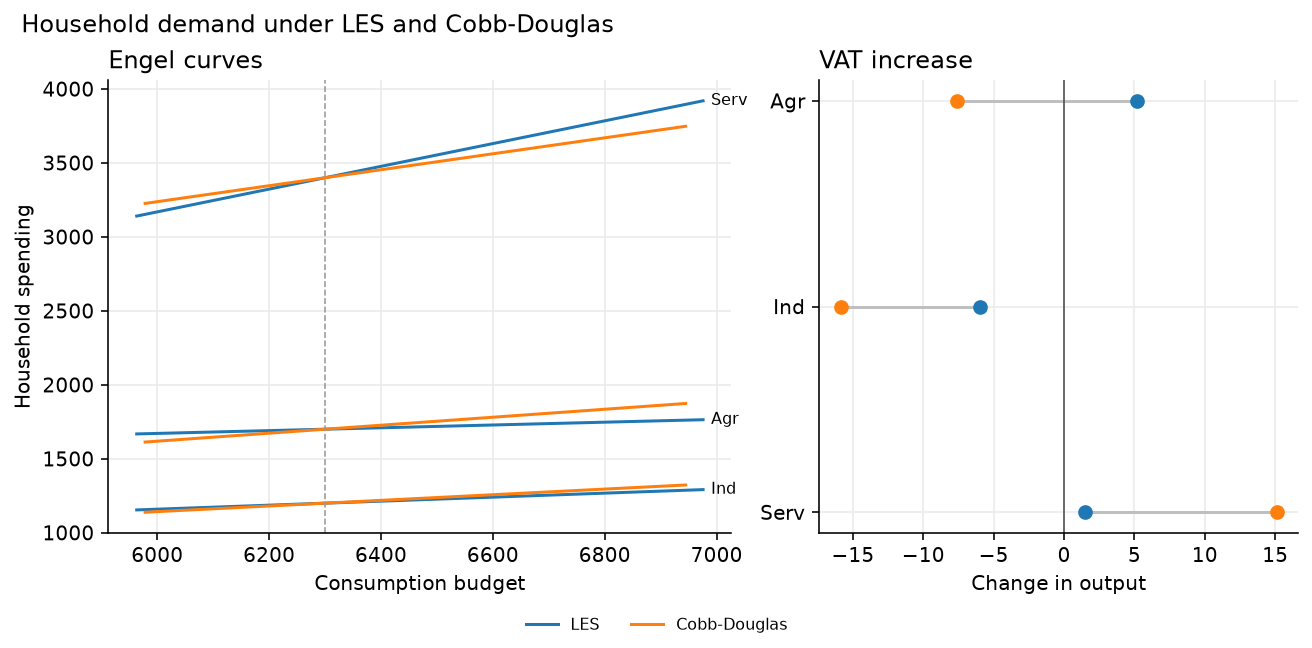

In [18]:
system_colors = {"LES": "C0",
                 "Cobb-Douglas": "C1"}
benchmark_budget = (1 - float(calibrated_values["mps"])) * float(calibrated_values["DISP_INC"])
production_changes = pd.DataFrame({name: change(result, "Y") for name, result in vat_rises.items()},
                                  index=sectors)
positions = np.arange(len(sectors))[::-1]

fig, (engel_ax, production_ax) = plt.subplots(ncols=2,
                                              figsize=(9, 4.4),
                                              dpi=144,
                                              layout="constrained",
                                              gridspec_kw={"width_ratios": [1.3, 1]})

for name, curves in engel.items():
    for sector in sectors:
        engel_ax.plot(curves.index,
                      curves[sector],
                      color=system_colors[name],
                      label=name if sector == sectors[0] else None)
for sector in sectors:
    engel_ax.annotate(sector,
                      xy=(engel["LES"].index[-1], engel["LES"][sector].iloc[-1]),
                      xytext=(4, 0),
                      textcoords="offset points",
                      va="center",
                      fontsize=8)
engel_ax.axvline(benchmark_budget,
                 color="0.6",
                 linewidth=0.8,
                 linestyle="--")
engel_ax.set(xlabel="Consumption budget",
             ylabel="Household spending")
engel_ax.set_title("Engel curves",
                   loc="left")

for sector, position in zip(sectors, positions):
    production_ax.plot(production_changes.loc[sector],
                       [position, position],
                       color="0.75",
                       linewidth=1.5,
                       zorder=1)
for name, color in system_colors.items():
    production_ax.scatter(production_changes[name],
                          positions,
                          color=color,
                          s=40,
                          zorder=2)
production_ax.axvline(0.0,
                      color="0.3",
                      linewidth=0.8)
production_ax.set(yticks=positions,
                  xlabel="Change in output")
production_ax.set_yticklabels(sectors)
production_ax.set_title("VAT increase",
                        loc="left")

for ax in (engel_ax, production_ax):
    ax.grid(color="0.92")
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Household demand under LES and Cobb-Douglas",
             x=0.01,
             ha="left")
handles, labels = engel_ax.get_legend_handles_labels()
fig.legend(handles=handles,
           labels=labels,
           loc="outside lower center",
           ncol=len(labels),
           frameon=False,
           fontsize=8)
plt.show()

Both demand systems reproduce benchmark spending, so their Engel curves cross at the benchmark budget, the dashed line. Under LES the services curve is steeper and the agriculture curve flatter, because households protect their subsistence spending on food and adjust mostly on services. Under Cobb-Douglas, spending on each good is a fixed share of the budget.

That difference decides the sectoral effect of the VAT increase. Government spending rises by almost the same amount under both systems, but under Cobb-Douglas households cut agriculture and industry more and services less. Agricultural output then falls by 7.6 instead of rising by 5.2, and services output rises by 15.1 instead of 1.5. The correction's account, in which government purchases replace household consumption good by good, holds because under LES the household cut falls mostly on services, the good the government buys most.

## Authors

- Created by Jesse Grabowski, November 26, 2026

## Watermark

In [19]:
%load_ext watermark
%watermark -n -u -v -iv -m -w -p pytensor

Last updated: Thu, 26 Nov 2026

Python implementation: CPython
Python version       : 3.12.13
IPython version      : 9.18.1

pytensor: 3.3.8

Compiler    : Clang 19.1.7 
OS          : Darwin
Release     : 25.6.0
Machine     : arm64
Processor   : arm
CPU cores   : 14
Architecture: 64bit

cge_modeling: 0.0.7.dev15+g93cb61e4e.d20261120
matplotlib  : 3.11.2
numpy       : 2.3.5
pandas      : 3.1.1

Watermark: 2.6.0

